<a href="https://colab.research.google.com/github/ElvisC1023746/PLN-ANALISIS-DE-SENTIMIENTOS-APPLE/blob/main/Proyecto3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

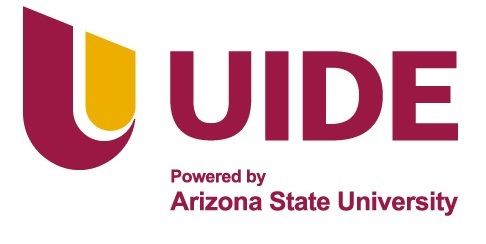

# PROYECTO INTEGRADOR DE SISTEMA IA APLICADA PARA ANÁLISIS PREDICTIVO

PROCESAMIENTO DE LENGUAJE NATURAL - ANÁLISIS DE SENTIMIENTOS EN CONSUMIDORES PRODUCTOS APPLE

Elaborado por Elvis Cóndor

4/11/2026


# Importación de Librerías

In [3]:
import re
import numpy as np
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt

from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score
)
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline

# Cargar Bases de Datos

In [4]:
df = pd.read_excel('AppleBD.xlsx')
print("Shape original:", df.shape)
print(df.head())

df = df[['Etiqueta', 'Sentimientos']].dropna()
print("Shape tras selección y limpieza de nulos:", df.shape)

print("\nDistribución de clases:")
print(df['Etiqueta'].value_counts())

Shape original: (5947, 2)
  Etiqueta                                       Sentimientos
0  Neutral        #aapl:the 10 best steve jobs emails ever...
1  Neutral  rt @jpdesloges: why aapl stock had a mini-flas...
2  Neutral  my cat only chews @apple cords. such an #apple...
3  Neutral  i agree with @jimcramer that the #individualin...
4  Neutral       nobody expects the spanish inquisition #aapl
Shape tras selección y limpieza de nulos: (5947, 2)

Distribución de clases:
Etiqueta
Neutral     3230
Negativo    2077
Positivo     640
Name: count, dtype: int64


# Transformación de Etiquetas a Target Numérico

In [5]:
target_map = {'Positivo': 1, 'Negativo': -1, 'Neutral': 0}
df['target'] = df['Etiqueta'].map(target_map)

if df['target'].isnull().any():
    print("Advertencia: hay etiquetas no mapeadas. Se eliminarán.")
    print(df[df['target'].isnull()]['Etiqueta'].unique())
    df = df.dropna(subset=['target'])

df['target'] = df['target'].astype(int)

# Procesamiento de Texto

In [6]:
def limpiar_texto(texto):
    if not isinstance(texto, str):
        return ""
    texto = texto.lower()
    texto = re.sub(r'http\S+|www\S+|https\S+', '', texto, flags=re.MULTILINE)
    texto = re.sub(r'@\w+|#\w+', '', texto)
    texto = re.sub(r'\s+', ' ', texto).strip()
    return texto

df['texto_limpio'] = df['Sentimientos'].apply(limpiar_texto)

print("\nEjemplo de texto original vs. limpio:")
for i in range(3):
    print("  ORIGINAL:", df['Sentimientos'].iloc[i])
    print("  LIMPIO  :", df['texto_limpio'].iloc[i])
    print()


Ejemplo de texto original vs. limpio:
  ORIGINAL: #aapl:the 10 best steve jobs emails ever...
  LIMPIO  : :the 10 best steve jobs emails ever...

  ORIGINAL: rt @jpdesloges: why aapl stock had a mini-flash crash today $aapl #aapl 
  LIMPIO  : rt : why aapl stock had a mini-flash crash today $aapl

  ORIGINAL: my cat only chews @apple cords. such an #applesnob.
  LIMPIO  : my cat only chews cords. such an .



# Balance de Datos Train/Test

In [7]:
df_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df['target']
)

print("Train:", df_train.shape, "| Test:", df_test.shape)
print("Distribución en train:\n", df_train['target'].value_counts(normalize=True))
print("Distribución en test:\n", df_test['target'].value_counts(normalize=True))

X_train_text = df_train['texto_limpio'].tolist()
X_test_text = df_test['texto_limpio'].tolist()
Y_train = df_train['target']
Y_test = df_test['target']

Train: (4757, 4) | Test: (1190, 4)
Distribución en train:
 target
 0    0.543199
-1    0.349170
 1    0.107631
Name: proportion, dtype: float64
Distribución en test:
 target
 0    0.542857
-1    0.349580
 1    0.107563
Name: proportion, dtype: float64


# Generación de Embeddings para Multi - Lenguaje

In [8]:
print("\nCargando modelo de embeddings multilingüe...")
embedder = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')

print("Generando embeddings para train...")
X_train_emb = embedder.encode(X_train_text, show_progress_bar=True)

print("Generando embeddings para test...")
X_test_emb = embedder.encode(X_test_text, show_progress_bar=True)

print("Shape embeddings train:", X_train_emb.shape)
print("Shape embeddings test:", X_test_emb.shape)


Cargando modelo de embeddings multilingüe...


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

... (9 outputs left out)

Batches:   0%|          | 0/149 [00:00<?, ?it/s]

Generando embeddings para test...


Batches:   0%|          | 0/38 [00:00<?, ?it/s]

Shape embeddings train: (4757, 384)
Shape embeddings test: (1190, 384)


# Búsqueda de Hiperparámetros Mediante Validación Cruzada

In [9]:
pipeline = Pipeline([
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

parametros = {
    'clf__C': [0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(
    pipeline,
    parametros,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

print("\nEjecutando GridSearchCV sobre embeddings...")
grid.fit(X_train_emb, Y_train)

print("\nMejores parámetros:", grid.best_params_)
print("Mejor F1 Macro (CV):", round(grid.best_score_, 4))


Ejecutando GridSearchCV sobre embeddings...
Fitting 5 folds for each of 5 candidates, totalling 25 fits

Mejores parámetros: {'clf__C': 100}
Mejor F1 Macro (CV): 0.7055


# Evaluación del Mejor Modelo para Mayor Precisión

In [10]:
best_model = grid.best_estimator_

P_train = best_model.predict(X_train_emb)
P_test = best_model.predict(X_test_emb)

print("\n--- MÉTRICAS EN TRAIN ---")
print("Accuracy:", round(accuracy_score(Y_train, P_train), 4))
print("F1 Macro:", round(f1_score(Y_train, P_train, average='macro'), 4))
print(classification_report(Y_train, P_train, target_names=['Negativo', 'Neutral', 'Positivo']))

print("\n--- MÉTRICAS EN TEST ---")
print("Accuracy:", round(accuracy_score(Y_test, P_test), 4))
print("F1 Macro:", round(f1_score(Y_test, P_test, average='macro'), 4))
print(classification_report(Y_test, P_test, target_names=['Negativo', 'Neutral', 'Positivo']))


--- MÉTRICAS EN TRAIN ---
Accuracy: 0.8316
F1 Macro: 0.811
              precision    recall  f1-score   support

    Negativo       0.83      0.85      0.84      1661
     Neutral       0.90      0.80      0.85      2584
    Positivo       0.62      0.92      0.74       512

    accuracy                           0.83      4757
   macro avg       0.78      0.86      0.81      4757
weighted avg       0.85      0.83      0.83      4757


--- MÉTRICAS EN TEST ---
Accuracy: 0.7597
F1 Macro: 0.7136
              precision    recall  f1-score   support

    Negativo       0.76      0.80      0.78       416
     Neutral       0.85      0.75      0.79       646
    Positivo       0.48      0.69      0.57       128

    accuracy                           0.76      1190
   macro avg       0.70      0.74      0.71      1190
weighted avg       0.78      0.76      0.77      1190



# Matrices de Confusión


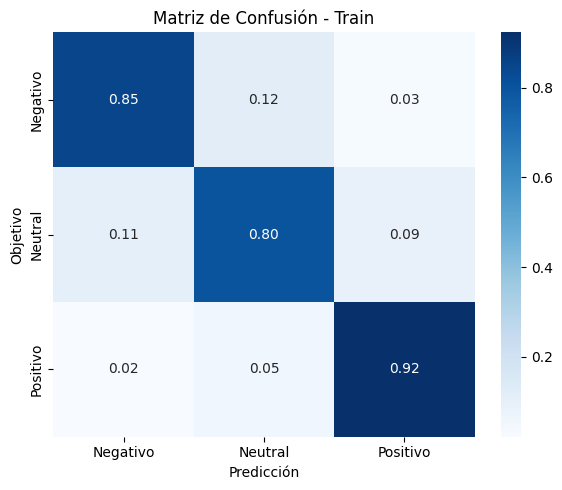

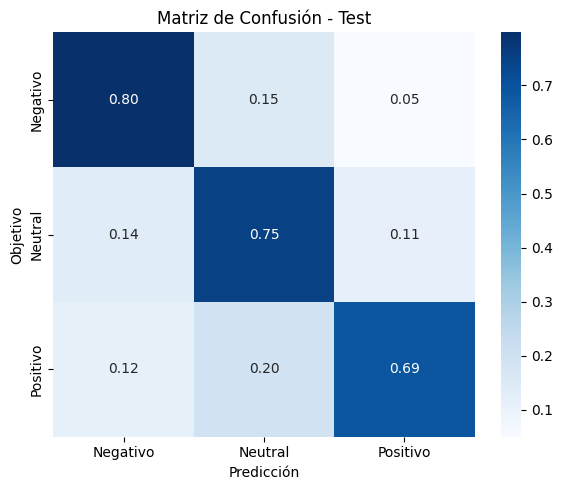

In [11]:
def plot_cm(cm, titulo):
    classes = ['Negativo', 'Neutral', 'Positivo']
    df_cm = pd.DataFrame(cm, index=classes, columns=classes)
    plt.figure(figsize=(6, 5))
    sn.heatmap(df_cm, annot=True, fmt='.2f', cmap='Blues')
    plt.xlabel('Predicción')
    plt.ylabel('Objetivo')
    plt.title(titulo)
    plt.tight_layout()
    plt.show()

cm_train = confusion_matrix(Y_train, P_train, normalize='true', labels=[-1, 0, 1])
plot_cm(cm_train, 'Matriz de Confusión - Train')

cm_test = confusion_matrix(Y_test, P_test, normalize='true', labels=[-1, 0, 1])
plot_cm(cm_test, 'Matriz de Confusión - Test')

# Predicción con Textos Nuevos

In [12]:
nombre_clase = {-1: 'Negativo', 0: 'Neutral', 1: 'Positivo'}

textos_prueba = {
    "Inglés": [
        "My iPhone heats up a lot and the battery drains incredibly fast",
        "Excellent product, the camera is amazing and performance is perfect",
        "The device arrived in good condition, it is a normal product",
        "The touch screen stopped working, very disappointed with Apple"
    ],
    "Español": [
        "El iPhone se calienta mucho y la batería se agota rapidísimo",
        "Excelente producto, la cámara es increíble y el rendimiento perfecto",
        "El equipo llegó en buen estado, es un producto normal",
        "No funciona el touch, muy decepcionado con Apple"
    ]
}

for idioma, lista_textos in textos_prueba.items():
    print(f"\n--- PREDICCIONES SOBRE TEXTOS NUEVOS ({idioma}) ---")
    textos_limpios = [limpiar_texto(t) for t in lista_textos]
    embeddings = embedder.encode(textos_limpios, show_progress_bar=False)
    predicciones = best_model.predict(embeddings)
    probabilidades = best_model.predict_proba(embeddings)

    for texto, pred, probs in zip(lista_textos, predicciones, probabilidades):
        print(f"\nTexto: {texto}")
        print(f"Predicción: {nombre_clase[pred]}")
        print(f"Probabilidades: Neg={probs[0]:.3f}, Neu={probs[1]:.3f}, Pos={probs[2]:.3f}")


--- PREDICCIONES SOBRE TEXTOS NUEVOS (Inglés) ---

Texto: My iPhone heats up a lot and the battery drains incredibly fast
Predicción: Negativo
Probabilidades: Neg=0.586, Neu=0.400, Pos=0.014

Texto: Excellent product, the camera is amazing and performance is perfect
Predicción: Positivo
Probabilidades: Neg=0.000, Neu=0.000, Pos=1.000

Texto: The device arrived in good condition, it is a normal product
Predicción: Positivo
Probabilidades: Neg=0.000, Neu=0.001, Pos=0.999

Texto: The touch screen stopped working, very disappointed with Apple
Predicción: Negativo
Probabilidades: Neg=0.953, Neu=0.019, Pos=0.028

--- PREDICCIONES SOBRE TEXTOS NUEVOS (Español) ---

Texto: El iPhone se calienta mucho y la batería se agota rapidísimo
Predicción: Negativo
Probabilidades: Neg=0.743, Neu=0.203, Pos=0.053

Texto: Excelente producto, la cámara es increíble y el rendimiento perfecto
Predicción: Positivo
Probabilidades: Neg=0.000, Neu=0.000, Pos=1.000

Texto: El equipo llegó en buen estado, es un pro